# Teaching Agentic RAG with LangGraph vs. Traditional RAG

In this notebook, we will demonstrate why **Agentic RAG** is a powerful advancement over **Standard RAG**.

### The Problem with Standard RAG
Standard RAG follows a rigid, linear path:
`User Query -> Retrieve Documents -> Generate Answer`.
If the retrieved documents are irrelevant, contains noise, or the generated answer doesn't address the query, Standard RAG fails because it has no way to self-correct, re-retrieve, or search alternative sources.

### The Agentic RAG Solution
Agentic RAG uses an LLM as a decision-making agent. Utilizing **LangGraph**, we can model RAG as a state machine with loops:
1. **Retrieve** documents.
2. **Grade** the retrieved documents for relevance.
3. **Rewrite/Refine** the query if the retrieved documents are not useful, and try retrieving again.
4. **Generate** an answer.
5. **Validate** the answer (hallucination checking and answer relevance).

In [ ]:
# Install necessary libraries
!pip install --quiet langchain langchain-community langgraph tiktoken chromadb langchain-openai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>

In [ ]:
# Install Gemini LangChain integrations
!pip install --quiet langchain-google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.3.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.


### Step 1: Create Dummy Knowledge Base
We will write local text files containing custom knowledge to act as our corpus.

In [ ]:
import os

# Create a couple of mock document files
os.makedirs('knowledge_base', exist_ok=True)

with open('knowledge_base/company_policy.txt', 'w') as f:
    f.write("""Company Policy:
Employees are allowed to work remotely up to 3 days a week.
Core collaboration hours are between 10 AM to 3 PM EST.
For travel expenses, employees must submit receipts within 30 days of returning.""")

with open('knowledge_base/benefits.txt', 'w') as f:
    f.write("""Health and Wellness Benefits:
We offer gold health insurance plans which cover dental and vision up to 80%.
An annual wellness stipend of $500 is provided for gym memberships or fitness equipment.""")

print("Knowledge base files created.")

Knowledge base files created.


### Step 2: Establish the Vector Store
We will index our created documents using standard LangChain document loaders, embeddings, and a vector database (Chroma).

In [ ]:
from langchain_community.document_loaders import DirectoryLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import Chroma
from langchain_google_genai import GoogleGenerativeAIEmbeddings

import os
if "GOOGLE_API_KEY" not in os.environ:
    from google.colab import userdata
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get("gemini_key")
    except Exception:
        print("Please configure your GOOGLE_API_KEY in Colab Secrets.")

# Load and split documents
loader = DirectoryLoader('knowledge_base', glob="*.txt", loader_cls=TextLoader)
docs = loader.load()
text_splitter = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=50)
splits = text_splitter.split_documents(docs)

# Vector Store with Google Gemini Embeddings
embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
vectorstore = Chroma.from_documents(documents=splits, embedding=embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

/tmp/ipykernel_569/3021490156.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import DirectoryLoader, TextLoader


### Step 3: Implement Standard (Linear) RAG
Let's see standard RAG implementation using LangChain's basic chain.

In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

# Initialize Gemini model
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0)

template = """Answer the question using only the following context:
{context}

Question: {question}
Answer:"""
prompt = ChatPromptTemplate.from_template(template)

def format_docs(docs):
    return "\n\n".join([d.page_content for d in docs])

# Standard RAG Chain using Gemini

# RunnablePassthrough is a core LangChain utility that passes inputs through
# a runnable chain unchanged, or with added keys.
#
# Why do we use it?
# 1. To pass data to the next step in a pipeline without modifications.

standard_rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)

# Testing with an out-of-bounds query
query = "How many days do I have to submit travel expense receipts and what is our policy on server deployment?"
print("Standard RAG Answer with Gemini:\n")
print(standard_rag_chain.invoke(query))

Standard RAG Answer with Gemini:



/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Based on the provided context, you have 30 days to submit travel expense receipts. The context does not contain any information regarding the policy on server deployment.


### Step 4: Implement Agentic RAG with LangGraph
Now, we'll build a state-machine workflow with **LangGraph** where an agent evaluates retrieved documents, decides if more steps are needed, and rewrites the query if the original search was insufficient.

In [ ]:
from typing import List, Dict, TypedDict
from langgraph.graph import StateGraph, END
from langchain_core.messages import BaseMessage, HumanMessage
from pydantic import BaseModel, Field

# Define the State dictionary
class GraphState(TypedDict):
    question: str
    generation: str
    documents: List[str]
    steps: List[str]

# Define the evaluation schema for structured outputs with Gemini
class GradeDocuments(BaseModel):
    binary_score: str = Field(description="Documents are relevant to the question, 'yes' or 'no'")

grade_llm = llm.with_structured_output(GradeDocuments)

grade_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are a grader assessing relevance of a retrieved document to a user question.
If the document contains keyword(s) or semantic meaning related to the user question, grade it as relevant.
Give a binary score 'yes' or 'no' score to indicate whether the document is relevant to the question."""),
    ("human", "Retrieved document: \n\n {document} \n\n User question: {question}")
])

retrieval_grader = grade_prompt | grade_llm

# --- Nodes ---

def retrieve(state: GraphState) -> Dict:
    print("--- RETRIEVING ---")
    question = state["question"]
    documents = retriever.invoke(question)
    doc_texts = [doc.page_content for doc in documents]
    return {"documents": doc_texts, "question": question, "steps": state.get("steps", []) + ["retrieve"]}

def generate(state: GraphState) -> Dict:
    print("--- GENERATING ---")
    question = state["question"]
    documents = state["documents"]

    context = "\n\n".join(documents)
    response = llm.invoke(f"Context:\n{context}\n\nQuestion: {question}\nAnswer:")
    return {"generation": response.content, "steps": state.get("steps", []) + ["generate"]}

def grade_documents(state: GraphState) -> Dict:
    print("--- GRADING DOCUMENTS ---")
    question = state["question"]
    documents = state["documents"]

    filtered_docs = []
    for doc in documents:
        res = retrieval_grader.invoke({"document": doc, "question": question})
        if res.binary_score == "yes":
            filtered_docs.append(doc)

    return {"documents": filtered_docs, "question": question, "steps": state.get("steps", []) + ["grade_docs"]}

def transform_query(state: GraphState) -> Dict:
    print("--- TRANSFORMING QUERY ---")
    question = state["question"]

    rewrite_prompt = f"Formulate a better search query to find information for: {question}. Provide only the new query text."
    better_question = llm.invoke(rewrite_prompt).content
    print(f"Rewrote query to: {better_question}")
    return {"question": better_question, "documents": state["documents"], "steps": state.get("steps", []) + ["transform_query"]}

def decide_to_generate(state: GraphState) -> str:
    print("--- DECIDING TO GENERATE ---")
    if not state["documents"]:
        print("No relevant documents found. Transforming query for retry...")
        return "transform_query"
    else:
        return "generate"

### Step 5: Construct the LangGraph State Machine
We will tie our defined functions/nodes together to map out the flow logic.

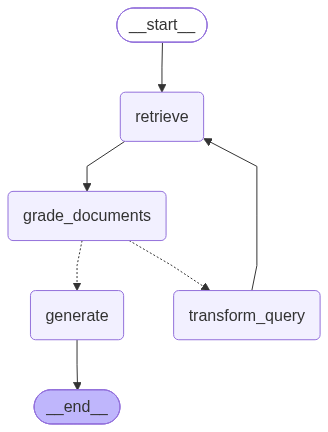

In [ ]:
from IPython.display import Image, display

workflow = StateGraph(GraphState)

# Define the nodes
workflow.add_node("retrieve", retrieve)
workflow.add_node("grade_documents", grade_documents)
workflow.add_node("generate", generate)
workflow.add_node("transform_query", transform_query)

# Build graph connections
workflow.set_entry_point("retrieve")
workflow.add_edge("retrieve", "grade_documents")
workflow.add_conditional_edges(
    "grade_documents",
    decide_to_generate,
    {
        "transform_query": "transform_query",
        "generate": "generate"
    }
)
workflow.add_edge("transform_query", "retrieve")
workflow.add_edge("generate", END)

# Compile
agentic_rag_app = workflow.compile()

# Visualize and print the graph
try:
    display(Image(agentic_rag_app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Could not display mermaid diagram directly: {e}")

### Step 6: Test and Compare
Now, let's run a query that might fail in a traditional RAG to demonstrate the decision-making power of Agentic RAG.

In [ ]:
# Run Agentic RAG
inputs = {"question": "What is our remote work policy on?"}
for output in agentic_rag_app.stream(inputs):
    for key, value in output.items():
        print(f"Node '{key}':")
print("\nFinal Agentic RAG Response:")
print(value["generation"])

--- RETRIEVING ---
Node 'retrieve':
--- GRADING DOCUMENTS ---


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


--- DECIDING TO GENERATE ---
Node 'grade_documents':
--- GENERATING ---


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Node 'generate':

Final Agentic RAG Response:
[{'type': 'text', 'text': 'Employees are allowed to work remotely up to 3 days a week.', 'extras': {'signature': 'EmAKXgFpFH0TlhxX3TVt8xKGkI0Pux3uKoGSeOXpxZHLSeq+xiS3BpopKVssrcDn0M7yLcghw/gghZpuRtQX/pm1GsjMQGAa9Z8a0xzvAOHQ+OKc/iHvA+DDF53HSe3JOOE='}}]


### Step 7: Human-in-the-Loop (HITL) Integration

Sometimes, letting an LLM autonomously rewrite search queries can lead to bad queries. We can integrate **Human-in-the-Loop (HITL)** using LangGraph's native state memory. By adding a thread memory checkpoint and using the `interrupt_before` configuration, we can pause execution right before `transform_query` and let a human moderator approve or override the search query.

In [ ]:
from langgraph.checkpoint.memory import MemorySaver

# We will reuse the same workflow, but compile it with a Memory Saver
# and an interrupt before we run 'transform_query'.
memory = MemorySaver()

agentic_rag_hitl_app = workflow.compile(
    checkpointer=memory,
    interrupt_before=["transform_query"]
)

#### Let's test the Interrupt Flow
We'll execute the graph with a complex prompt containing irrelevant noise to trigger the document grader's negative response, which forces the state machine to route towards the query transformation step.

In [ ]:
config = {"configurable": {"thread_id": "1"}}
initial_inputs = {"question": "What is our policy to deploy docker containers?"}

print("=== Starting the flow (will pause before transforming query) ===")
for event in agentic_rag_hitl_app.stream(initial_inputs, config):
    for key, value in event.items():
        print(f"Completed Node: '{key}'")

# Check if the execution is paused
state = agentic_rag_hitl_app.get_state(config)
print(f"\nIs execution paused? {'Yes' if state.next else 'No'}")
print(f"Next planned node execution: {state.next}")
print(f"Current query stored in state: '{state.values.get('question')}'")

=== Starting the flow (will pause before transforming query) ===
--- RETRIEVING ---
Completed Node: 'retrieve'
--- GRADING DOCUMENTS ---


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


--- DECIDING TO GENERATE ---
No relevant documents found. Transforming query for retry...
Completed Node: 'grade_documents'
Completed Node: '__interrupt__'

Is execution paused? Yes
Next planned node execution: ('transform_query',)
Current query stored in state: 'What is our policy to deploy docker containers?'


#### Intervene: Human Overrides the State
Now, as a human teacher/moderator, we can manually change the query inside the graph's state storage to ignore the irrelevant information and direct it strictly to remote work details before we resume the engine.

In [ ]:
# The human overrides the state with a cleaner, hand-crafted query
print("=== Human intervention: Manually correcting the question state ===")
agentic_rag_hitl_app.update_state(
    config,
    {"question": "What is our policy on working remotely?"},
    as_node="transform_query"
)

print("State updated successfully.")

=== Human intervention: Manually correcting the question state ===
State updated successfully.


#### Resume the Flow
Once corrected, we resume graph execution simply by passing `None` as inputs, keeping the original configuration reference.

In [ ]:
print("=== Resuming flow with the manually updated state ===")
for event in agentic_rag_hitl_app.stream(None, config):
    for key, value in event.items():
        print(f"Completed Node: '{key}'")

# Get final evaluation
final_state = agentic_rag_hitl_app.get_state(config)
print("\nFinal Output after human correction:")
print(final_state.values.get("generation"))

=== Resuming flow with the manually updated state ===
--- RETRIEVING ---
Completed Node: 'retrieve'
--- GRADING DOCUMENTS ---


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


--- DECIDING TO GENERATE ---
Completed Node: 'grade_documents'
--- GENERATING ---


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Completed Node: 'generate'

Final Output after human correction:
[{'type': 'text', 'text': 'Employees are allowed to work remotely up to 3 days a week.', 'extras': {'signature': 'EmAKXgFpFH0TGwxmVPhVMqZ9slGJ380spzU69OBk4xzjnsNvPqCX8Oi3kwkFRbBTnM3L0gWdn58CRyXhmrwFlohjQ39/tZCRW4cT+OImO6BWT0LOrnFw+7435qqApwQZfvU='}}]
